# Task 2: Exploratory Data Analysis
**Author: Ishita Misra | WeIntern Week 2**
Explore descriptive statistics, distributions, relationships, category/region performance, and monthly trends. This is synthetic practice data. Unfiltered totals represent recorded sales across completed, returned, and cancelled orders, not net accounting revenue. No causal effects are claimed. Unknown regions remain a data-quality bucket and are excluded from geographic performance rankings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')
# Resolve project root in a repository checkout or a Colab Drive folder.
from pathlib import Path
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent,
    Path('/content/drive/MyDrive/retail-sales-week2')]
    if (p / 'data/raw/retail_sales_raw.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the extracted retail-sales-week2 folder; see README for Colab setup.')

DATA_PATH = PROJECT_ROOT / 'data/processed/retail_sales_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'reports/eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH, parse_dates=['order_date','ship_date'])
assert not df.isna().any().any()
assert not df.duplicated().any()
print('Dataset:', df.shape)
print('Date range:',df.order_date.min(), 'to',df.order_date.max())
display(df.head())
df.info()

Dataset: (11923, 21)
Date range: 2023-01-01 00:00:00 to 2025-12-31 00:00:00
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11923 entries, 0 to 11922
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          11923 non-null  object        
 1   order_date        11923 non-null  datetime64[ns]
 2   ship_date         11923 non-null  datetime64[ns]
 3   store_id          11923 non-null  object        
 4   region            11923 non-null  object        
 5   customer_segment  11923 non-null  object        
 6   product_id        11923 non-null  object        
 7   product_name      11923 non-null  object        
 8   product_category  11923 non-null  object        
 9   quantity          11923 non-null  float64       
 10  unit_price        11923 non-null  float64       
 11  discount          11923 non-null  float64       
 12  promotion         11923 non-null  object        
 13  

    order_id order_date  ship_date store_id   region customer_segment product_id   product_name        product_category  quantity  unit_price  discount      promotion     sales  cost_price  shipping_cost   profit payment_method sales_channel  holiday_flag order_status
0  ORD000001 2023-04-08 2023-04-10    ST101    north         consumer      P3001  Running Shoes                 fashion       7.0  3022.96000     0.082  festival sale  19890.12     1610.25          5.960  8612.41            upi      in-store             0     returned
1  ORD000002 2025-04-28 2025-05-01    ST303     east         consumer      P5001   Skincare Kit  beauty & personal care       3.0  1351.45000     0.107   no promotion   4574.92      657.02        100.970  2502.89           cash        online             0    completed
2  ORD000003 2024-12-18 2024-12-18    ST401     west         consumer      P2003   Bedsheet Set          home & kitchen       5.0  1614.89000     0.072   no promotion   9323.44      756.38     

## Descriptive statistics
Mean, median, spread, quartiles, and skewness describe numeric columns; frequencies summarize categories.

In [2]:
numeric_cols = df.select_dtypes('number').columns
numeric_stats = df[numeric_cols].describe().T
numeric_stats['median'] = df[numeric_cols].median()
numeric_stats['skewness'] = df[numeric_cols].skew()
display(numeric_stats.round(2))
display(df.describe(include=['object']).T)
numeric_stats.to_csv(OUTPUT_DIR/'descriptive_statistics.csv')

                 count      mean       std       min      25%      50%      75%        max   median  skewness
quantity       11923.0      3.20      1.46      1.00     2.00     3.00     4.00       7.00     3.00      0.53
unit_price     11923.0   2028.28   1807.22    166.32   507.92  1568.26  2920.94    6542.12  1568.26      1.30
discount       11923.0      0.10      0.06      0.00     0.06     0.10     0.14       0.95     0.10      1.07
sales          11923.0  17167.91  46739.36    149.11  1652.59  4334.66  9818.33  519928.33  4334.66      5.09
cost_price     11923.0   3526.40   9293.04    103.67   236.53   785.68  1610.34   47225.34   785.68      3.60
shipping_cost  11923.0     34.94     28.27      0.00    10.35    29.20    58.22     123.23    29.20      0.50
profit         11923.0   6034.42  15451.33 -23369.78   785.53  2108.66  4719.72  265251.76  2108.66      6.61
holiday_flag   11923.0      0.26      0.44      0.00     0.00     0.00     1.00       1.00     0.00      1.09

                  count unique           top   freq
order_id          11923  11923     ORD000001      1
store_id          11923     15         ST302    836
region            11923      6         south   2397
customer_segment  11923      4      consumer   8367
product_id        11923     20         P3002    685
product_name      11923     20   Denim Jeans    685
product_category  11923      6       fashion   2631
promotion         11923      4  no promotion   6266
payment_method    11923      6           upi   4450
sales_channel     11923      3      in-store   7366
order_status      11923      3     completed  11226

## Distributions: histogram and KDE
Compare means and medians to assess skew. Extreme values are retained observations, not automatically errors.

Sales mean: 17167.91 | median: 4334.66 | skew: 5.09


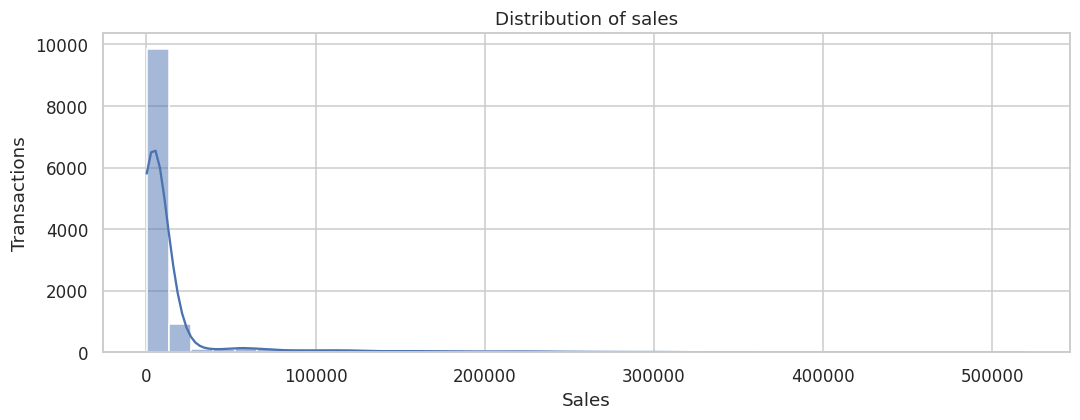

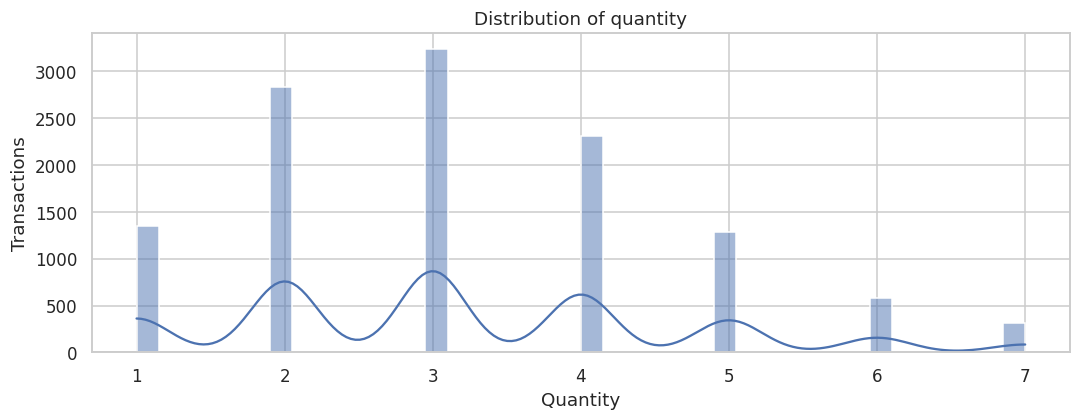

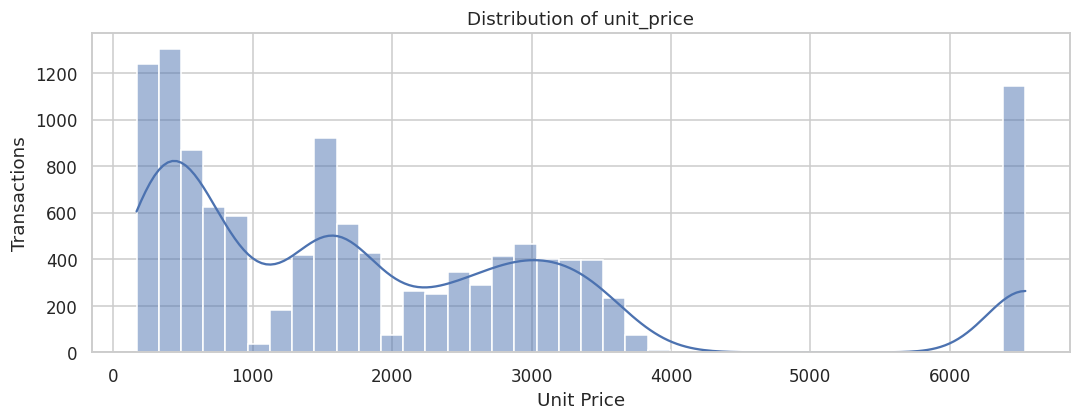

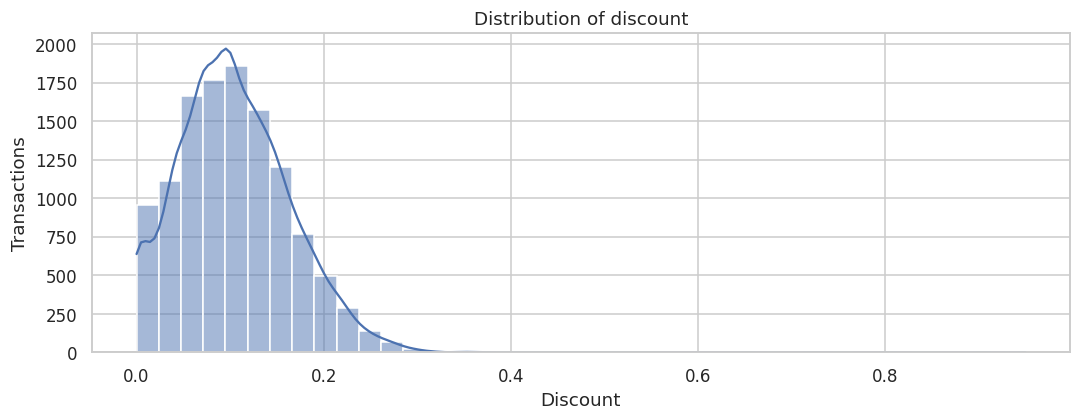

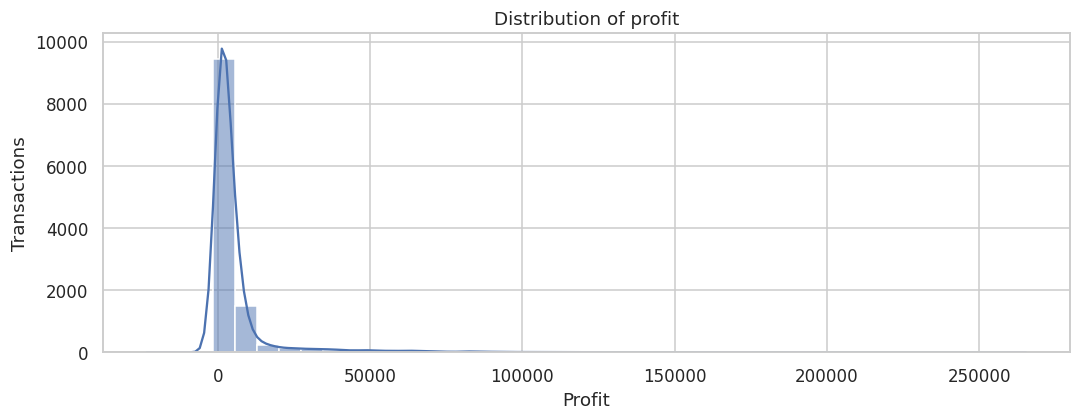

In [3]:
for col in ['sales','quantity','unit_price','discount','profit']:
    fig,ax=plt.subplots(figsize=(10,4))
    sns.histplot(data=df,x=col,kde=True,bins=40,ax=ax)
    ax.set(title=f'Distribution of {col}',ylabel='Transactions',xlabel=col.replace('_',' ').title())
    plt.tight_layout();plt.show()
print('Sales mean:',round(df.sales.mean(),2),'| median:',round(df.sales.median(),2),'| skew:',round(df.sales.skew(),2))

## Correlation heatmap
Pearson correlation measures linear association. Profit is derived partly from sales, so their correlation is not independent evidence of causation and profit must not predict sales.

Discount vs sales correlation: -0.037


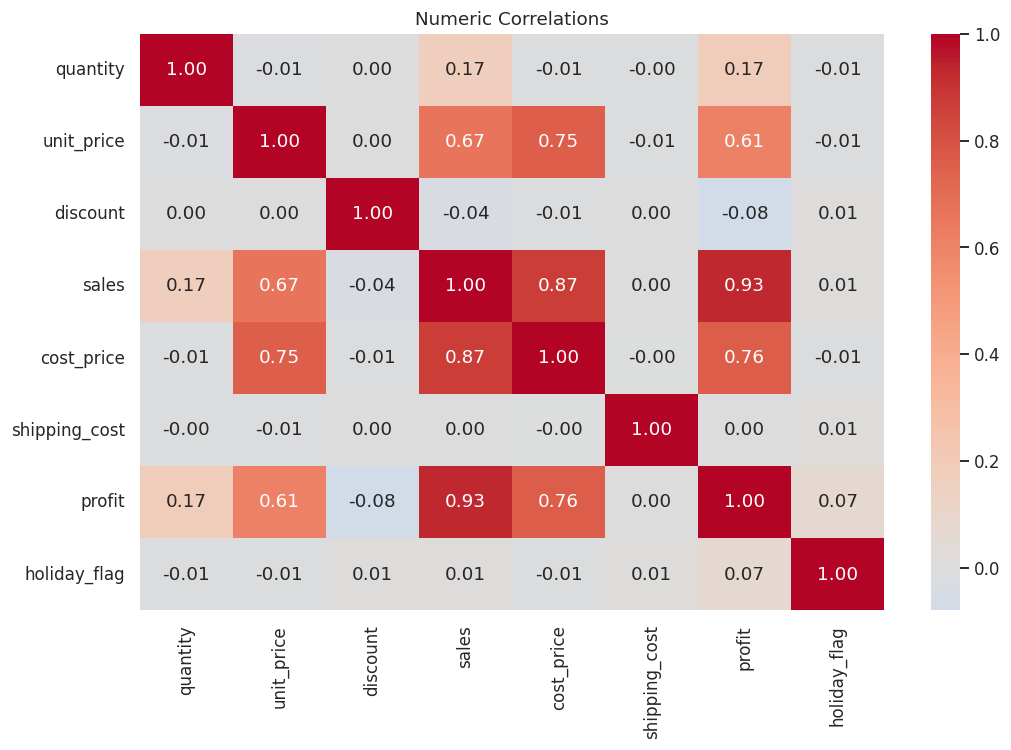

In [4]:
corr_matrix = df[numeric_cols].corr()
plt.figure(figsize=(10,7));sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Numeric Correlations');plt.tight_layout();plt.show()
corr_matrix.to_csv(OUTPUT_DIR/'correlation_matrix.csv')
print('Discount vs sales correlation:',round(df.discount.corr(df.sales),3))

## Category performance: bar chart and box plot
Total sales reflect both order volume and transaction size. Compare totals with transaction counts and distribution.

                         total_sales  average_sales  transactions  total_profit  sales_share_percent
product_category                                                                                    
electronics             1.586342e+08       66934.28          2370   49412880.54                77.50
home & kitchen          1.746812e+07        6987.25          2500    8043625.06                 8.53
fashion                 1.631883e+07        6202.52          2631    8866790.17                 7.97
beauty & personal care  7.075731e+06        3808.25          1858    3683916.81                 3.46
grocery                 3.746542e+06        1532.33          2445    1407221.32                 1.83
unknown                 1.449536e+06       12180.98           119     533917.85                 0.71

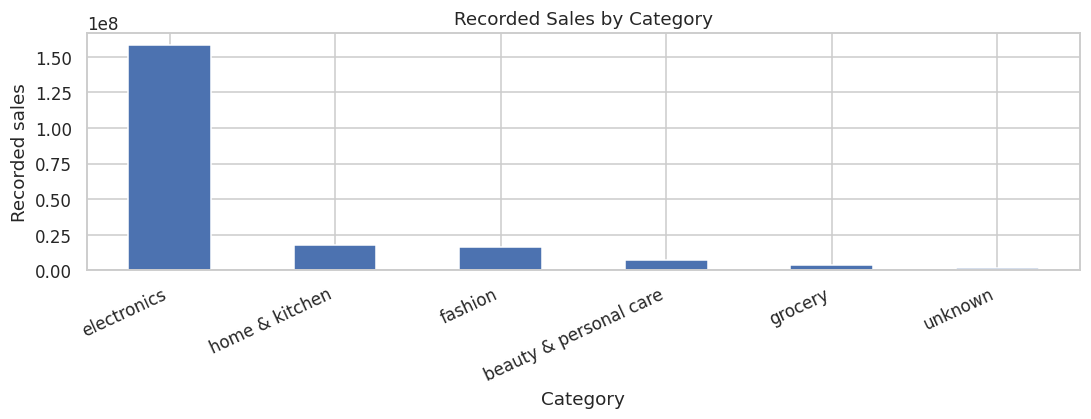

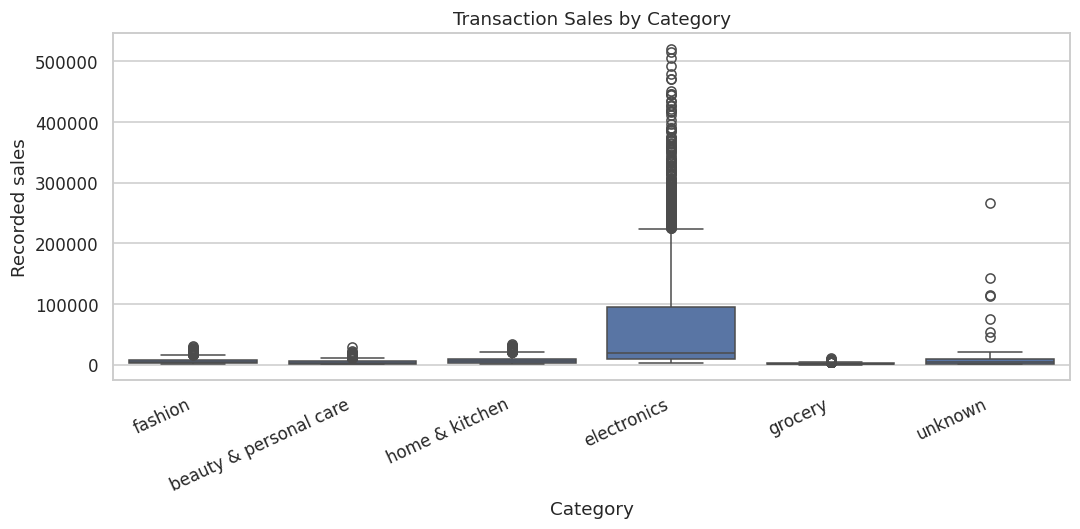

In [5]:
category_summary = df.groupby('product_category').agg(total_sales=('sales','sum'),average_sales=('sales','mean'),transactions=('sales','size'),total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
category_summary['sales_share_percent']=100*category_summary.total_sales/df.sales.sum()
display(category_summary.round(2))
category_summary.total_sales.plot.bar(figsize=(10,4),title='Recorded Sales by Category')
plt.ylabel('Recorded sales');plt.xlabel('Category');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
plt.figure(figsize=(10,5));sns.boxplot(data=df,x='product_category',y='sales')
plt.title('Transaction Sales by Category');plt.xlabel('Category');plt.ylabel('Recorded sales');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
category_summary.to_csv(OUTPUT_DIR/'category_sales_summary.csv')

## Regional performance
Unknown labels are shown separately and are not a geographic region.

Unknown-region rows: 144


         total_sales  transactions  total_profit
region                                          
central  41479793.71          2363   14917043.94
south    41457341.02          2397   14697390.37
north    40243593.89          2322   13622036.90
west     40212732.37          2339   14540886.10
east     38866345.03          2358   13326212.81
unknown   2433185.13           144     844781.63

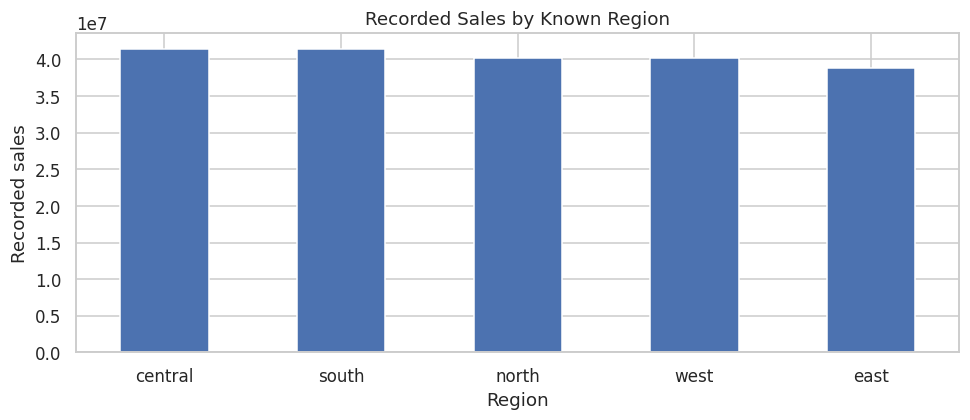

In [6]:
region_summary=df.groupby('region').agg(total_sales=('sales','sum'),transactions=('sales','size'),total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
known_regions=region_summary.drop(index='unknown',errors='ignore')
display(region_summary.round(2))
known_regions.total_sales.plot.bar(figsize=(9,4),title='Recorded Sales by Known Region')
plt.ylabel('Recorded sales');plt.xlabel('Region');plt.xticks(rotation=0);plt.tight_layout();plt.show()
print('Unknown-region rows:',int(df.region.eq('unknown').sum()))
region_summary.to_csv(OUTPUT_DIR/'regional_sales_summary.csv')

## Monthly trends: line chart
Peaks may reflect order volume or product mix; this chart alone does not establish stable seasonality.

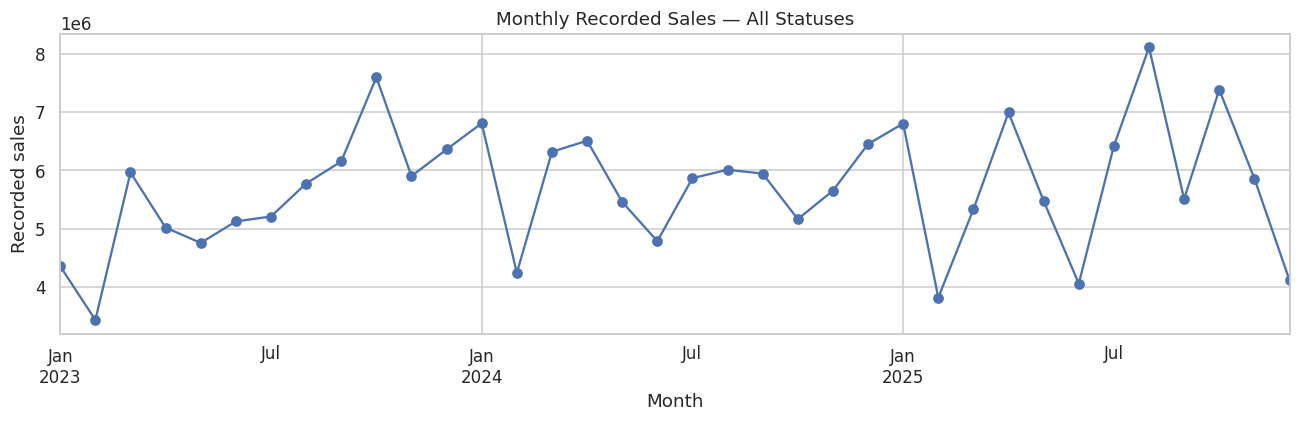

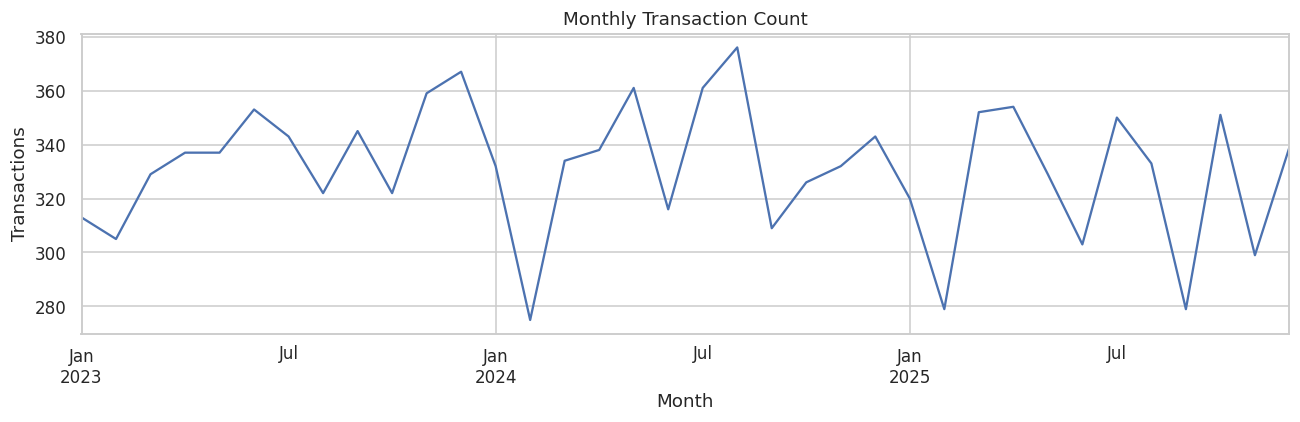

In [7]:
monthly_summary=df.set_index('order_date').resample('MS').agg(total_sales=('sales','sum'),transactions=('sales','size'),average_sales=('sales','mean'))
monthly_summary.total_sales.plot(figsize=(12,4),title='Monthly Recorded Sales — All Statuses',marker='o')
plt.ylabel('Recorded sales');plt.xlabel('Month');plt.tight_layout();plt.show()
monthly_summary.transactions.plot(figsize=(12,4),title='Monthly Transaction Count')
plt.ylabel('Transactions');plt.xlabel('Month');plt.tight_layout();plt.show()
monthly_summary.to_csv(OUTPUT_DIR/'monthly_sales_summary.csv')

## Discount and sales: scatter plot
Assess the point cloud and correlation; product mix confounds comparisons.

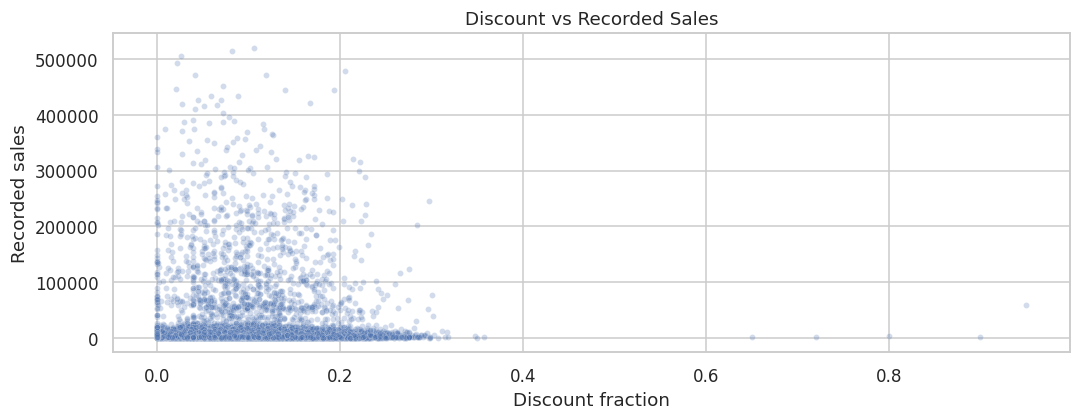

               total_profit  average_profit  transactions
discount_band                                            
No discount      3300323.74         8685.06           380
Up to 10%       39658790.28         6911.61          5738
10–20%          26385120.81         5213.42          5061
20–30%           2542259.67         3492.11           728
Above 30%          61857.25         3866.08            16

In [8]:
plt.figure(figsize=(10,4));sns.scatterplot(data=df,x='discount',y='sales',alpha=.25,s=15)
plt.title('Discount vs Recorded Sales');plt.xlabel('Discount fraction');plt.ylabel('Recorded sales');plt.tight_layout();plt.show()
discount_df=df.assign(discount_band=pd.cut(df.discount,[-.001,0,.1,.2,.3,1],labels=['No discount','Up to 10%','10–20%','20–30%','Above 30%']))
discount_summary=discount_df.groupby('discount_band',observed=False).agg(total_profit=('profit','sum'),average_profit=('profit','mean'),transactions=('sales','size'))
display(discount_summary.round(2))
discount_summary.to_csv(OUTPUT_DIR/'discount_band_summary.csv')

## Order statuses and data-quality limitations
Completed-only sales are a separate measure. Returns require a defined accounting rule before computing net revenue. Independent cleaning of quantity and price also means transaction arithmetic need not reconcile.

Completed-only sales: 192,427,623.40
Exact duplicate rows: 0 | repeated IDs: 0
Records not reconciling with quantity × price × (1-discount), tolerance 1: 11897


              transactions  recorded_sales  recorded_profit
order_status                                               
cancelled              217    3.980776e+06       1457672.20
completed            11226    1.924276e+08      67400102.57
returned               480    8.284592e+06       3090576.98

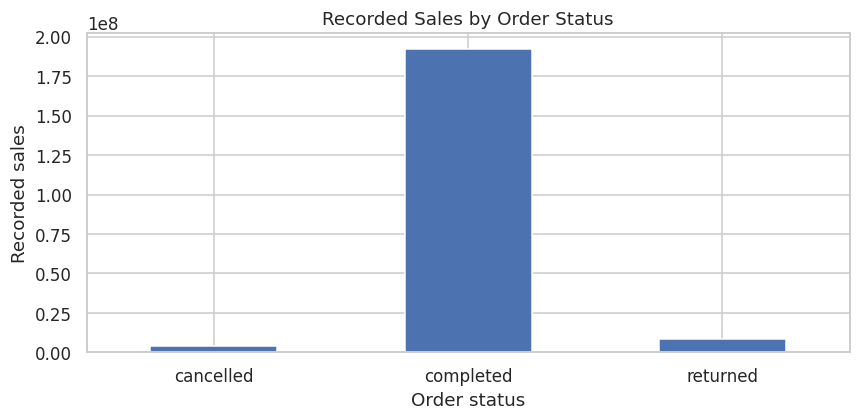

In [9]:
status_summary=df.groupby('order_status').agg(transactions=('sales','size'),recorded_sales=('sales','sum'),recorded_profit=('profit','sum'))
display(status_summary.round(2))
status_summary.recorded_sales.plot.bar(figsize=(8,4),title='Recorded Sales by Order Status')
plt.ylabel('Recorded sales');plt.xlabel('Order status');plt.xticks(rotation=0);plt.tight_layout();plt.show()
completed=df[df.order_status.eq('completed')]
print('Completed-only sales:',f'{completed.sales.sum():,.2f}')
print('Exact duplicate rows:',df.duplicated().sum(),'| repeated IDs:',df.order_id.duplicated().sum())
print('Records not reconciling with quantity × price × (1-discount), tolerance 1:',int((abs(df.sales-df.quantity*df.unit_price*(1-df.discount))>1).sum()))
status_summary.to_csv(OUTPUT_DIR/'status_sales_summary.csv')

## Findings and recommendations
The following insights are computed from the current cleaned CSV, so they remain consistent after rerunning Task 1.

In [10]:
top=category_summary.iloc[0]
low=known_regions.iloc[-1]
peak=monthly_summary.total_sales.idxmax()
band=discount_summary.loc[discount_summary.transactions.gt(0),'average_profit'].idxmax()
insights=[
 f'1. {category_summary.index[0]} contributes {top.sales_share_percent:.2f}% of recorded sales. Review product mix, unusually large transactions, and profitability before prioritizing stock.',
 f'2. {known_regions.index[-1]} has the lowest known-region recorded sales ({low.total_sales:,.2f}). Compare transaction counts and product mix before changing budgets; unknown labels are excluded.',
 f'3. {band} has the highest mean recorded profit per transaction. Compare sample size, product mix, and completed-only outcomes before changing discount policy.',
 f'4. {peak:%B %Y} has the highest monthly recorded sales ({monthly_summary.loc[peak,"total_sales"]:,.2f}). Investigate promotions, transaction volume, category mix, and order statuses.'
]
for insight in insights:print(insight+'\n')
(OUTPUT_DIR/'insights.md').write_text('# EDA Findings\n\n'+'\n\n'.join(insights)+'\n\nSynthetic observational data; results are descriptive and do not establish causation. Recorded sales across all statuses are not realized net revenue.')

1. electronics contributes 77.50% of recorded sales. Review product mix, unusually large transactions, and profitability before prioritizing stock.

2. east has the lowest known-region recorded sales (38,866,345.03). Compare transaction counts and product mix before changing budgets; unknown labels are excluded.

3. No discount has the highest mean recorded profit per transaction. Compare sample size, product mix, and completed-only outcomes before changing discount policy.

4. August 2025 has the highest monthly recorded sales (8,106,887.18). Investigate promotions, transaction volume, category mix, and order statuses.



## Conclusion
The analysis includes histograms/KDE, a heatmap, bar charts, box plots, line charts, and a scatter plot. Use the computed insights as investigation priorities. Confirm synthetic-data assumptions and transaction formulas, investigate unknown regions, and distinguish recorded totals from completed-order sales. These results describe this dataset; they are not validated business forecasts.